In [ ]:
!pip -q install tokenizers gensim scikit-learn matplotlib numpy

import numpy as np
import matplotlib.pyplot as plt
import itertools
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

np.random.seed(42)

# Pula A: zamek jako budowla (16 zdań)
pula_a = [
    'Ten zamek jest bardzo stary', 'Król zbudował nowy zamek',
    'Wysoka brama prowadzi przez zamek', 'Zamek ma wielki mur',
    'Rycerz chroni ten zamek', 'Zamek leży na górze',
    'Ten zamek ma dużą wieżę', 'Zamek otacza wysoki mur',
    'Król lubi swój zamek', 'Stary zamek jest piękny',
    'Zamek odwiedzają turyści', 'Zamek stoi nad rzeką',
    'Zamek ma gruby mur', 'Rycerz kocha stary zamek',
    'Zamek to duża budowla', 'Wieża zdobi ten zamek'
]

# Pula B: zamek jako mechanizm/suwak (16 zdań)
pula_b = [
    'Ten zamek w drzwiach jest zepsuty', 'Zamek wymaga szybkiej naprawy',
    'Nowy klucz otwiera zamek', 'Zamek w drzwiach jest nowy',
    'Metalowy zamek jasno błyszczy', 'Kurtka ma zepsuty zamek',
    'Zamek zacina się mocno', 'Napraw ten zepsuty zamek',
    'Klucz szybko zamyka zamek', 'Kurtka ma dobry zamek',
    'Zamek blokuje te drzwi', 'Zamek działa bardzo płynnie',
    'Ten zamek jest z metalu', 'Zamek chroni nasze drzwi',
    'Złoty klucz przekręca zamek', 'Metalowy zamek to zamek'
]

# Pula C: tło, bez słowa "zamek" (20 zdań)
pula_c = [
    'Kot lubi pić ciepłe mleko', 'Pies biega po dużym lesie',
    'Mały kot śpi smacznie', 'Drzewo rośnie bardzo wysoko',
    'Ptak lata nad zielonym polem', 'Słońce świeci na niebie',
    'Samochód jedzie przez miasto', 'Rower stoi pod domem',
    'Chłopak pije ciepłą wodę', 'Dziewczyna czyta ciekawą książkę',
    'Kot patrzy na małego ptaka', 'Pies szuka nowej kości',
    'Drzewo traci zielone liście', 'Słońce mocno grzeje w lecie',
    'Samochód jest bardzo szybki', 'Chłopak biega po dużym parku',
    'Dziewczyna uczy się pilnie', 'Rower ma dwa okrągłe koła',
    'Ptak śpiewa na wysokim drzewie', 'Woda szybko płynie w rzece'
]

def preprocess(sentences):
    return [s.lower().replace('.', '') for s in sentences]

pula_a_prep = preprocess(pula_a)
pula_b_prep = preprocess(pula_b)
pula_c_prep = preprocess(pula_c)
pelny_korpus = pula_a_prep + pula_b_prep + pula_c_prep

In [ ]:
print("TOKENIZACJA BPE")
pary_form = {
    'widziane': ['kot', 'drzewo', 'klucz', 'brama', 'rycerz', 'rzeka'],
    'niewidziane': ['koty', 'drzewami', 'kluczem', 'bramy', 'rycerzowi', 'rzekach']
}

rozmiary = [60, 100, 200]
wyniki_bpe = {}

for v_size in rozmiary:
    t = Tokenizer(models.BPE(unk_token='[UNK]'))
    t.pre_tokenizer = pre_tokenizers.Whitespace()
    tr = trainers.BpeTrainer(vocab_size=v_size, special_tokens=['[UNK]'], min_frequency=1)
    t.train_from_iterator(pelny_korpus, tr)

    faktyczny_rozmiar = t.get_vocab_size()

    for nazwa_grupy, formy in pary_form.items():
        tokeny_suma = 0
        formy_z_unk = 0
        for w in formy:
            enc = t.encode(w).tokens
            tokeny_suma += len(enc)
            if '[UNK]' in enc:
                formy_z_unk += 1

        srednia = tokeny_suma / len(formy)
        wyniki_bpe[(v_size, nazwa_grupy)] = (faktyczny_rozmiar, srednia, formy_z_unk)

print("Tabela wyników BPE:")
print(f"{'Limit':<8} | {'Faktyczny |V|':<15} | {'Grupa':<12} | {'Średnia tokenów':<15} | {'Formy z [UNK]':<15}")
for (v, grp), (f_v, avg, unk) in wyniki_bpe.items():
    print(f"{v:<8} | {f_v:<15} | {grp:<12} | {avg:<15.2f} | {unk:<15}")

print("Podział 2 niewidzianych form:")
for v_size in rozmiary:
    t = Tokenizer(models.BPE(unk_token='[UNK]'))
    t.pre_tokenizer = pre_tokenizers.Whitespace()
    t.train_from_iterator(pelny_korpus, trainers.BpeTrainer(vocab_size=v_size, special_tokens=['[UNK]'], min_frequency=1))
    print(f"Limit {v_size}: 'koty' -> {t.encode('koty').tokens}, 'kluczem' -> {t.encode('kluczem').tokens}")

=== 2. TOKENIZACJA BPE ===
Tabela wyników BPE:
Limit    | Faktyczny |V|   | Grupa        | Średnia tokenów | Formy z [UNK]  
60       | 60              | widziane     | 3.50            | 0              
60       | 60              | niewidziane  | 4.67            | 0              
100      | 100             | widziane     | 3.00            | 0              
100      | 100             | niewidziane  | 4.00            | 0              
200      | 200             | widziane     | 1.50            | 0              
200      | 200             | niewidziane  | 3.00            | 0              

Podział 2 niewidzianych form:
Limit 60: 'koty' -> ['ko', 't', 'y'], 'kluczem' -> ['k', 'lu', 'cz', 'e', 'm']
Limit 100: 'koty' -> ['ko', 'ty'], 'kluczem' -> ['klu', 'cz', 'e', 'm']
Limit 200: 'koty' -> ['ko', 'ty'], 'kluczem' -> ['klucz', 'e', 'm']


In [ ]:
print("SĄSIEDZI WORD2VEC")
# Wariant 1: zamek jako budowla dominuje (12 zdań A, 4 zdania B, 20 zdań C)
wariant_1 = pula_a_prep[:12] + pula_b_prep[:4] + pula_c_prep
# Wariant 2: zamek jako mechanizm dominuje (4 zdania A, 12 zdań B, 20 zdań C)
wariant_2 = pula_a_prep[:4] + pula_b_prep[:12] + pula_c_prep

zdania_w1 = [s.split() for s in wariant_1]
zdania_w2 = [s.split() for s in wariant_2]

# Trenujemy modele Word2Vec
w2v_1 = Word2Vec(zdania_w1, vector_size=20, window=3, min_count=1, sg=1, epochs=500, seed=42, workers=1)
w2v_2 = Word2Vec(zdania_w2, vector_size=20, window=3, min_count=1, sg=1, epochs=500, seed=42, workers=1)

print("5 najbliższych sąsiadów dla 'zamek' w Modelu 1 (budowla):")
print([(s, round(v,3)) for s,v in w2v_1.wv.most_similar('zamek', topn=5)])

print("\n5 najbliższych sąsiadów dla 'zamek' w Modelu 2 (mechanizm):")
print([(s, round(v,3)) for s,v in w2v_2.wv.most_similar('zamek', topn=5)])

=== 3. SĄSIEDZI WORD2VEC ===
5 najbliższych sąsiadów dla 'zamek' w Modelu 1 (budowla):
[('ten', 0.965), ('rycerz', 0.936), ('mur', 0.935), ('piękny', 0.925), ('jest', 0.92)]

5 najbliższych sąsiadów dla 'zamek' w Modelu 2 (mechanizm):
[('klucz', 0.943), ('nowy', 0.935), ('ten', 0.929), ('zepsuty', 0.92), ('kurtka', 0.919)]


=== 4. RZUT PCA I KOSINUS ===


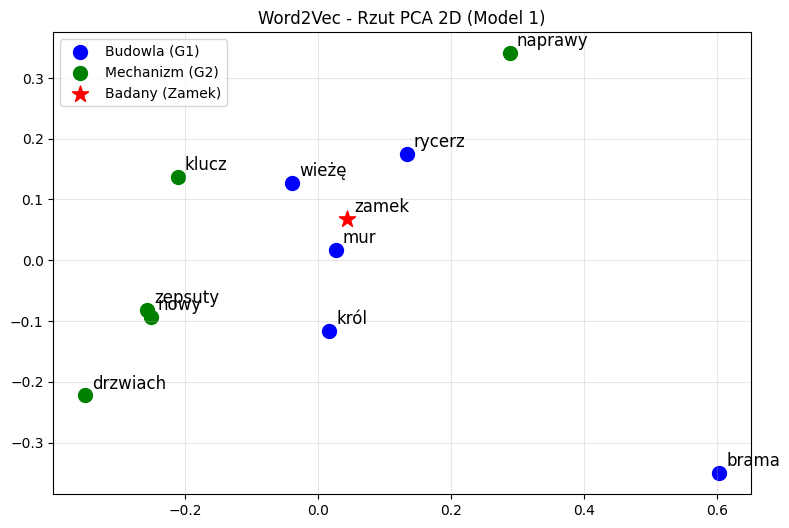

Średnie podobieństwo wewnątrz grupy 1 (Budowla): 0.898
Średnie podobieństwo wewnątrz grupy 2 (Mechanizm): 0.871
Średnie podobieństwo między grupą 1 a 2: 0.856


In [ ]:
print("RZUT PCA I KOSINUS")
g1_budowla = ['król', 'rycerz', 'mur', 'wieżę', 'brama']
g2_mechanizm = ['klucz', 'drzwiach', 'naprawy', 'nowy', 'zepsuty']
badany_wyraz = 'zamek'

slowa_pca = g1_budowla + g2_mechanizm + [badany_wyraz]
V = np.stack([w2v_1.wv[w] for w in slowa_pca])
XY = PCA(n_components=2, random_state=42).fit_transform(V)

plt.figure(figsize=(9, 6))
# Rysowanie punktów grupami
idx_g1 = range(len(g1_budowla))
idx_g2 = range(len(g1_budowla), len(g1_budowla) + len(g2_mechanizm))
idx_cel = len(slowa_pca) - 1

plt.scatter(XY[idx_g1, 0], XY[idx_g1, 1], color='blue', label='Budowla (G1)', s=100)
plt.scatter(XY[idx_g2, 0], XY[idx_g2, 1], color='green', label='Mechanizm (G2)', s=100)
plt.scatter(XY[idx_cel, 0], XY[idx_cel, 1], color='red', label='Badany (Zamek)', s=150, marker='*')

for (x, y), w in zip(XY, slowa_pca):
    plt.annotate(w, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=12)

plt.title('Word2Vec - Rzut PCA 2D (Model 1)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Obliczanie średniego podobieństwa cosinusowego
def cos_sim(w1, w2):
    return np.dot(w1, w2) / (np.linalg.norm(w1) * np.linalg.norm(w2))

# G1 wewnątrz
cos_g1 = [cos_sim(w2v_1.wv[a], w2v_1.wv[b]) for a, b in itertools.combinations(g1_budowla, 2)]
# G2 wewnątrz
cos_g2 = [cos_sim(w2v_1.wv[a], w2v_1.wv[b]) for a, b in itertools.combinations(g2_mechanizm, 2)]
# G1 vs G2
cos_miedzy = [cos_sim(w2v_1.wv[a], w2v_1.wv[b]) for a, b in itertools.product(g1_budowla, g2_mechanizm)]

print(f"Średnie podobieństwo wewnątrz grupy 1 (Budowla): {np.mean(cos_g1):.3f}")
print(f"Średnie podobieństwo wewnątrz grupy 2 (Mechanizm): {np.mean(cos_g2):.3f}")
print(f"Średnie podobieństwo między grupą 1 a 2: {np.mean(cos_miedzy):.3f}")